In [1]:
pip install gymnasium

In [2]:
import gymnasium as gym
import math
import random
import matplotlib
import matplotlib.pyplot as plt
from collections import namedtuple, deque
from itertools import count

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

import numpy as np

In [3]:
# Инициализация среды
env = gym.make("CartPole-v1")

# set up matplotlib
is_ipython = 'inline' in matplotlib.get_backend()
if is_ipython:
    from IPython import display
# Настройка matplotlib для отображения графиков
plt.ion()

# Определение устройства (GPU или CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
# Определяем namedtuple для хранения перехода (состояние, действие, следующее состояние, награда, флаг завершения)
Transition = namedtuple('Transition', ('state', 'action', 'next_state', 'reward', 'done'))

class ReplayMemory(object):

    def __init__(self, capacity):
        # Инициализация буфера воспроизведения с заданной емкостью
        self.memory = deque([], maxlen=capacity)  # Используем deque для хранения переходов

    def push(self, *args):
        # Сохраняет переход в буфере
        self.memory.append(Transition(*args))  # Добавляем переход в буфер

    def sample(self, batch_size):
        # Случайно выбирает batch_size переходов из буфера
        return random.sample(self.memory, batch_size)  # Возвращаем случайную выборку переходов

    def __len__(self):
        # Возвращает текущее количество переходов в буфере
        return len(self.memory)  # Возвращаем длину буфера

In [5]:
class DQN(nn.Module):
    # Реализация нейронной сети DQN
    def __init__(self, n_observations, n_actions):
        super(DQN, self).__init__()
        # Первый полносвязный слой: вход n_observations, выход 128
        self.layer1 = nn.Linear(n_observations, 128)
        # Второй полносвязный слой: вход 128, выход 128
        self.layer2 = nn.Linear(128, 128)
        # Третий полносвязный слой: вход 128, выход n_actions
        self.layer3 = nn.Linear(128, n_actions)

    def forward(self, x):
        # Прямой проход через сеть
        x = F.relu(self.layer1(x))  # Применяем первый слой и ReLU
        x = F.relu(self.layer2(x))  # Применяем второй слой и ReLU
        return self.layer3(x)  # Возвращаем Q-значения

In [6]:
# BATCH_SIZE - количество переходов, выбираемых из буфера воспроизведения для обучения
# GAMMA - коэффициент дисконтирования (учитывает будущие награды)
# EPS_START - начальное значение epsilon (для epsilon-greedy стратегии)
# EPS_END - конечное значение epsilon
# EPS_DECAY - скорость уменьшения epsilon (чем больше, тем медленнее уменьшение)
# TAU - скорость обновления целевой сети (soft update)
# LR - скорость обучения для оптимизатора AdamW
BATCH_SIZE = 128
GAMMA = 0.99
EPS_START = 0.9
EPS_END = 0.05
EPS_DECAY = 1000
TAU = 0.005
LR = 1e-4

# Получаем количество возможных действий из пространства действий среды
n_actions = env.action_space.n
# Получаем начальное состояние среды и информацию
state, info = env.reset()
# Определяем размерность состояния
n_observations = len(state)

# Инициализируем основную нейронную сеть
policy_net = DQN(n_observations, n_actions).to(device)
# Инициализируем целевую нейронную сеть
target_net = DQN(n_observations, n_actions).to(device)
# Копируем веса из основной сети в целевую
target_net.load_state_dict(policy_net.state_dict())

# Инициализируем оптимизатор AdamW для основной сети
optimizer = optim.AdamW(policy_net.parameters(), lr=LR, amsgrad=True)
# Инициализируем буфер воспроизведения с емкостью 10000 переходов
memory = ReplayMemory(10000)

# Счетчик шагов для epsilon-greedy стратегии
steps_done = 0


def select_action(state):
    global steps_done
    # Генерируем случайное число для определения, будет ли действие случайным или выбирается моделью
    sample = random.random()
    # Вычисляем текущий порог для epsilon-жадной стратегии
    eps_threshold = EPS_END + (EPS_START - EPS_END) * \
        math.exp(-1. * steps_done / EPS_DECAY)
    steps_done += 1  # Увеличиваем счетчик шагов
    if sample > eps_threshold:
        # Если случайное число больше порога, выбираем действие с помощью policy_net
        with torch.no_grad():
            # policy_net(state) возвращает Q-значения для всех действий
            # max(1) возвращает максимальное Q-значение и его индекс (действие)
            # indices.view(1, 1) преобразует результат в нужный формат
            return policy_net(state).max(1).indices.view(1, 1)
    else:
        # Иначе выбираем случайное действие из пространства действий среды
        return torch.tensor([[env.action_space.sample()]], device=device, dtype=torch.long)


# Список для хранения длительности каждого эпизода
episode_durations = []


def plot_durations(show_result=False):
    plt.figure(1)
    # Преобразуем список длительностей в тензор
    durations_t = torch.tensor(episode_durations, dtype=torch.float)
    if show_result:
        plt.title('Result')  # Заголовок для финального графика
    else:
        plt.clf()  # Очищаем текущий график
        plt.title('Training...')  # Заголовок для графика во время обучения
    plt.xlabel('Episode')  # Подпись оси X
    plt.ylabel('Duration')  # Подпись оси Y
    plt.plot(durations_t.numpy())  # Отображаем длительности эпизодов
    # Если есть достаточно данных, вычисляем скользящее среднее за 100 эпизодов
    if len(durations_t) >= 100:
        means = durations_t.unfold(0, 100, 1).mean(1).view(-1)
        means = torch.cat((torch.zeros(99), means))  # Добавляем нули для выравнивания
        plt.plot(means.numpy())  # Отображаем скользящее среднее

    plt.pause(0.001)  # Делаем паузу для обновления графика
    if is_ipython:
        if not show_result:
            display.display(plt.gcf())  # Отображаем текущий график в Jupyter
            display.clear_output(wait=True)  # Очищаем вывод для обновления
        else:
            display.display(plt.gcf())  # Отображаем финальный график

In [7]:
def optimize_model():
    # Если в памяти недостаточно переходов для формирования батча, выходим из функции
    if len(memory) < BATCH_SIZE:
        return

    # Выбираем случайный батч переходов из памяти
    transitions = memory.sample(BATCH_SIZE)

    # Транспонируем батч (преобразуем список переходов в переход списков)
    # Подробнее: https://stackoverflow.com/a/19343/3343043
    batch = Transition(*zip(*transitions))

    # Создаем маску для нефинальных состояний (состояний, после которых симуляция не завершилась)
    non_final_mask = torch.tensor(tuple(map(lambda s: s is not None,
                                          batch.next_state)), device=device, dtype=torch.bool)
    # Собираем все нефинальные следующие состояния в один тензор
    non_final_next_states = torch.cat([s for s in batch.next_state
                                                if s is not None])

    # Собираем батчи для состояний, действий и наград
    state_batch = torch.cat(batch.state)
    action_batch = torch.cat(batch.action)
    reward_batch = torch.cat(batch.reward)

    # Вычисляем Q(s_t, a) - значения Q-функции для текущих состояний и выбранных действий
    # policy_net(state_batch) возвращает Q-значения для всех действий, а gather выбирает значения для конкретных действий
    state_action_values = policy_net(state_batch).gather(1, action_batch)

    # Вычисляем V(s_{t+1}) для всех следующих состояний
    # Для нефинальных состояний используем target_net для предсказания Q-значений и выбираем максимальные значения
    # Для финальных состояний значение равно 0
    next_state_values = torch.zeros(BATCH_SIZE, device=device)
    with torch.no_grad():
        next_state_values[non_final_mask] = target_net(non_final_next_states).max(1).values

    # Вычисляем ожидаемые значения Q-функции с учетом награды и дисконтирования
    expected_state_action_values = (next_state_values * GAMMA) + reward_batch

    # Вычисляем Huber loss (SmoothL1Loss) между предсказанными и ожидаемыми значениями
    criterion = nn.SmoothL1Loss()
    loss = criterion(state_action_values, expected_state_action_values.unsqueeze(1))

    # Оптимизация модели
    optimizer.zero_grad()  # Обнуляем градиенты
    loss.backward()  # Вычисляем градиенты
    # Обрезаем градиенты, чтобы избежать взрыва градиентов
    torch.nn.utils.clip_grad_value_(policy_net.parameters(), 100)
    optimizer.step()  # Обновляем параметры модели

Complete


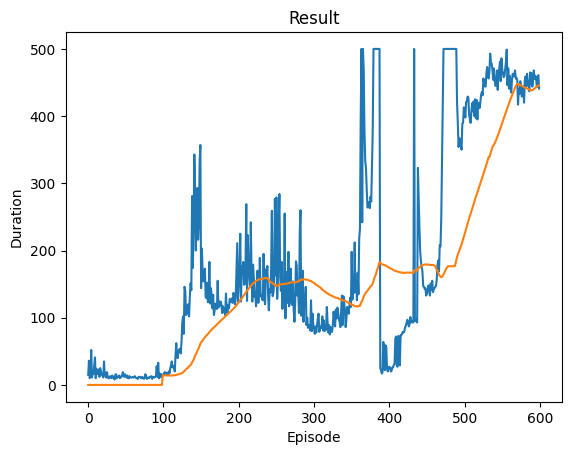

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [9]:
# Проверяем, доступен ли CUDA (использование GPU для ускорения вычислений)
if torch.cuda.is_available():
    num_episodes = 600  # Если CUDA доступен, устанавливаем больше эпизодов
else:
    num_episodes = 50  # Если CUDA недоступен, устанавливаем меньше эпизодов

# Основной цикл обучения по эпизодам
for i_episode in range(num_episodes):
    # Инициализируем среду и получаем начальное состояние
    state, info = env.reset()
    # Преобразуем состояние в тензор и добавляем размерность для батча
    state = torch.tensor(state, dtype=torch.float32, device=device).unsqueeze(0)

    # Внутренний цикл для каждого шага в эпизоде
    for t in count():
        # Выбираем действие на основе текущего состояния
        action = select_action(state)
        # Выполняем действие в среде и получаем новое состояние, награду и флаги завершения
        observation, reward, terminated, truncated, _ = env.step(action.item())
        # Преобразуем награду в тензор
        reward = torch.tensor([reward], device=device)
        # Определяем, завершен ли эпизод (терминирован или усечен)
        done = terminated or truncated

        # Если эпизод завершен, следующее состояние равно None
        if terminated:
            next_state = None
        else:
            # Иначе преобразуем новое состояние в тензор и добавляем размерность для батча
            next_state = torch.tensor(observation, dtype=torch.float32, device=device).unsqueeze(0)

        # Сохраняем переход (состояние, действие, следующее состояние, награда, done) в память
        memory.push(state, action, next_state, reward, done)  # Добавлен аргумент done

        # Переходим к следующему состоянию
        state = next_state

        # Выполняем один шаг оптимизации модели (обновление политики)
        optimize_model()

        # Мягкое обновление весов целевой сети
        # θ′ ← τ θ + (1 −τ )θ′
        target_net_state_dict = target_net.state_dict()
        policy_net_state_dict = policy_net.state_dict()
        for key in policy_net_state_dict:
            # Обновляем веса целевой сети с учетом весов политической сети
            target_net_state_dict[key] = policy_net_state_dict[key]*TAU + target_net_state_dict[key]*(1-TAU)
        # Загружаем обновленные веса в целевую сеть
        target_net.load_state_dict(target_net_state_dict)

        # Если эпизод завершен, сохраняем длительность эпизода и отображаем график
        if done:
            episode_durations.append(t + 1)
            plot_durations()
            break

# Выводим сообщение о завершении обучения
print('Complete')
# Отображаем итоговый график длительности эпизодов
plot_durations(show_result=True)
plt.ioff()
plt.show()

В начале линия низкая, так как агент только начинает исследовать среду и действует случайно.
Далее линия начинает расти, так как агент находит более эффективные стратегии. Агент исследует среду, пробует разные стратегии, и иногда это приводит к ухудшению результатов. Линия стабилизируется, что может означать, что агент достиг максимально возможного результата.